## Bank customer churn


In [ ]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier

In [ ]:
df = pd.read_csv('/Users/alem/Documents/Data Analyst/SQL projects/Bank Customer Churn/bank_customer_churn_cleaned.csv')

In [4]:
first_ten = df.head(10)
first_ten

,CustomerID,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCreditCard,IsActiveMember,EstimatedSalary,Exited,Complain,SatisfactionsScore,CardType,PointEarned
0,15634602,Bernard,619,France,Female,42,2,549.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,15604732,Bernard,483,France,Female,30,9,5706.00,2,0,0,136356.97,0,0,3,PLATINUM,970
2,15789863,Bernard,683,France,Male,39,4,8908.00,2,1,0,171716.81,0,0,2,GOLD,913
3,15704583,Durand,651,France,Male,56,2,378.00,1,1,0,114522.68,1,1,4,GOLD,327
4,15595388,Bernard,594,France,Female,30,10,8252.00,2,1,1,124071.71,0,0,2,DIAMOND,757
5,15633531,Bernard,717,France,Female,76,9,138489.66,1,1,1,68400.14,0,0,2,GOLD,860
6,15705379,Bernard,678,France,Male,38,3,4219.00,2,1,0,66561.60,0,0,1,SILVER,331
7,15597983,Bernard,692,France,Male,69,10,154953.94,1,1,1,70849.47,0,0,3,SILVER,648
8,15754537,Bernard,748,France,Male,40,0,6881.00,1,0,0,60416.76,0,0,4,SILVER,724
9,15597131,Leroy,415,France,Male,32,5,145807.59,1,1,1,3064.65,0,0,2,PLATINUM,833


### Column descriptions

**RowNumber:**  corresponds to the record (row) number and has no effect on the output.

**CustomerId:**  contains random values and has no effect on customer leaving the bank.

**Surname:**  the surname of a customer has no impact on their decision to leave the bank.

**CreditScore:**  can have an effect on customer churn, since a customer with a higher credit score is less likely to leave the bank.

**Geography:**  a customer’s location can affect their decision to leave the bank.

**Gender:**  it’s interesting to explore whether gender plays a role in a customer leaving the bank.

**Age:**  this is certainly relevant, since older customers are less likely to leave their bank than younger ones.

**Tenure:**  refers to the number of years that the customer has been a client of the bank. Normally, older clients 
are more loyal and less likely to leave a bank.

**Balance:**  also a very good indicator of customer churn, as people with a higher balance in their accounts are 
less likely to leave the bank compared to those with lower balances.

**NumOfProducts:**  refers to the number of products that a customer has purchased through the bank.

**HasCrCard:**  denotes whether or not a customer has a credit card. This column is also relevant, since people with a credit card are less likely to leave the bank.

**IsActiveMember:**  active customers are less likely to leave the bank.

**EstimatedSalary:**  as with balance, people with lower salaries are more likely to leave the bank compared to those with higher salaries.

**Exited:**  whether or not the customer left the bank.

**Complain:**  customer has complaint or not.

**SatisfactionScore:**  Score provided by the customer for their complaint resolution.


**CardType:**  type of card hold by the customer.

**PointsEarned:**  the points earned by the customer for using credit card.
)

Now we can check some basic **dataframe** information.

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CustomerID          10000 non-null  int64  
 1   Surname             10000 non-null  object 
 2   CreditScore         10000 non-null  int64  
 3   Geography           10000 non-null  object 
 4   Gender              10000 non-null  object 
 5   Age                 10000 non-null  int64  
 6   Tenure              10000 non-null  int64  
 7   Balance             10000 non-null  float64
 8   NumOfProducts       10000 non-null  int64  
 9   HasCreditCard       10000 non-null  int64  
 10  IsActiveMember      10000 non-null  int64  
 11  EstimatedSalary     10000 non-null  float64
 12  Exited              10000 non-null  int64  
 13  Complain            10000 non-null  int64  
 14  SatisfactionsScore  10000 non-null  int64  
 15  CardType            10000 non-null  object 
 16  Point

Now let's check summary statistics for numerical columns with **'df.describe( )'** command.

In [6]:
df.describe()

,CustomerID,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCreditCard,IsActiveMember,EstimatedSalary,Exited,Complain,SatisfactionsScore,PointEarned
count,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,1.569094e+07,650.528800,38.921800,5.012800,78125.373488,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,7.193619e+04,96.653299,10.487806,2.892174,60413.974301,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.556570e+07,350.000000,18.000000,0.000000,14.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,1.562853e+07,584.000000,32.000000,3.000000,6309.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


We should check if there are duplicate values such as CustomerID.

In [7]:
unique = len(pd.unique(df['CustomerID']))
unique

10000

In [8]:
df.shape

(10000, 17)

So we can see thate there's no duplicate values.

In [9]:
df.isnull().sum()

CustomerID            0
Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCreditCard         0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
SatisfactionsScore    0
CardType              0
PointEarned           0
dtype: int64

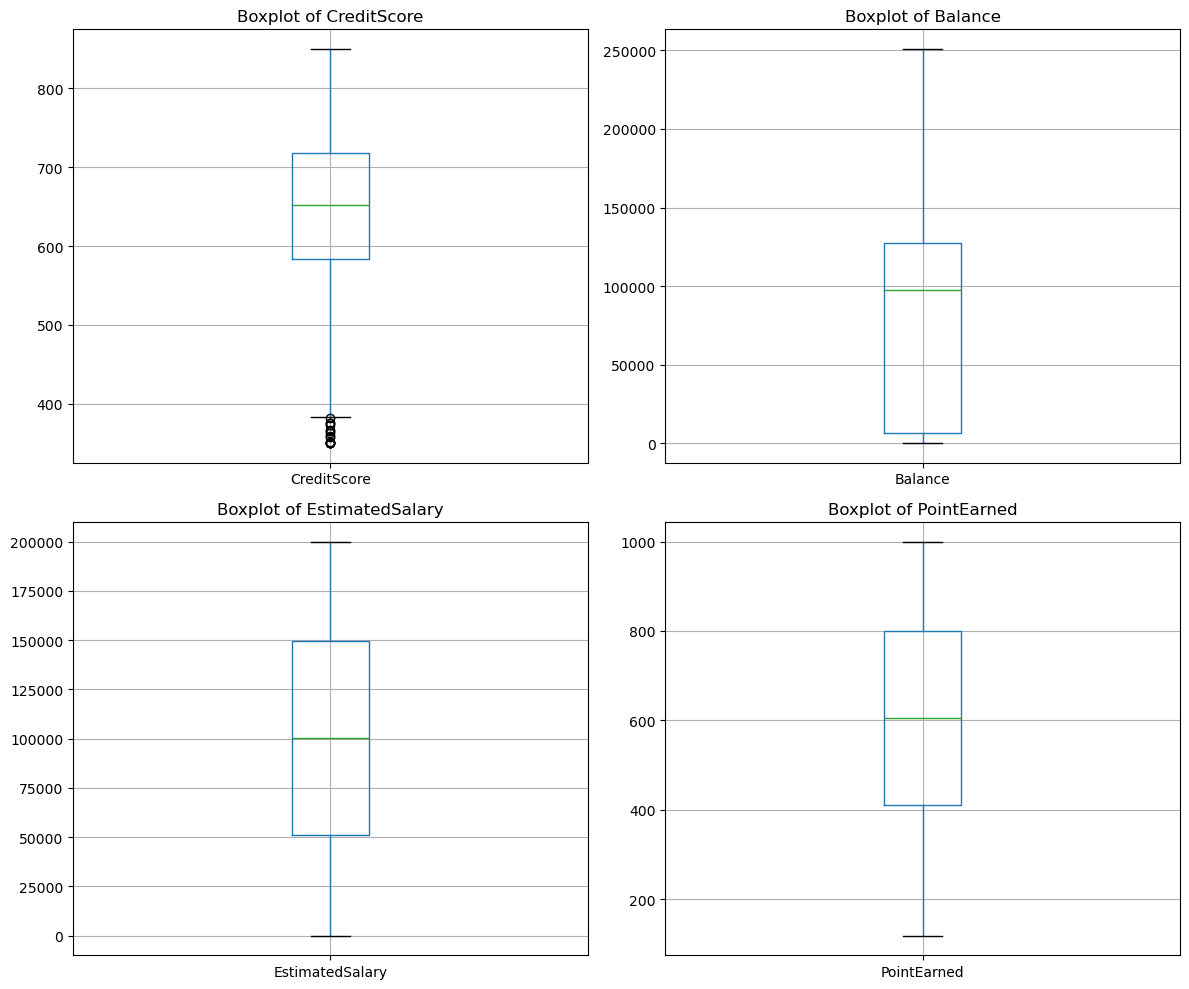

In [10]:
boxplots = ['CreditScore', 'Balance', 'EstimatedSalary', 'PointEarned']
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
axes = axes.flatten()  

for i, column in enumerate(boxplots):
    df.boxplot(column=[column], ax=axes[i])
    axes[i].set_title(f'Boxplot of {column}')

plt.tight_layout() 
plt.show()


From these boxplots above we can see **outliers** on the "CreditScore" boxplot. So let's check them.

In [11]:
Q1 = df['CreditScore'].quantile(0.25)
Q3 = df['CreditScore'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['CreditScore'] < lower_bound) | (df['CreditScore'] > upper_bound)]

In [12]:
outliers

,CustomerID,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCreditCard,IsActiveMember,EstimatedSalary,Exited,Complain,SatisfactionsScore,CardType,PointEarned
1853,15668309,Laurent,350,France,Female,40,0,111098.85,1,1,1,172321.21,1,1,2,DIAMOND,670
2004,15803202,Lefebvre,350,France,Male,51,10,6190.00,1,1,1,125823.79,1,1,4,GOLD,383
3166,15758813,Hoffmann,350,Germany,Male,39,0,109733.20,2,0,0,123602.11,1,1,2,GOLD,261
3956,15597896,Wagner,365,Germany,Male,30,0,127760.07,1,1,0,81537.85,1,1,4,DIAMOND,342
4687,15692416,Jiménez,358,Spain,Female,52,8,143542.36,3,1,0,141959.11,1,1,4,SILVER,976
4723,15792650,Jiménez,382,Spain,Male,36,0,7478.00,1,1,1,179540.73,1,1,4,GOLD,659
5348,15765173,Lefebvre,350,France,Female,60,3,3684.00,1,0,0,113796.15,1,1,1,SILVER,958
6364,15612494,Richard,359,France,Female,44,6,128747.69,1,1,0,146955.71,1,1,1,PLATINUM,981
6493,15734711,Petit,373,France,Male,42,7,7262.00,1,1,0,77786.37,1,1,3,GOLD,986
6730,15804586,Robert,376,France,Female,46,6,2644.00,1,1,0,157333.69,1,1,2,PLATINUM,979


Let's compare column **Exited** with the rest columns.

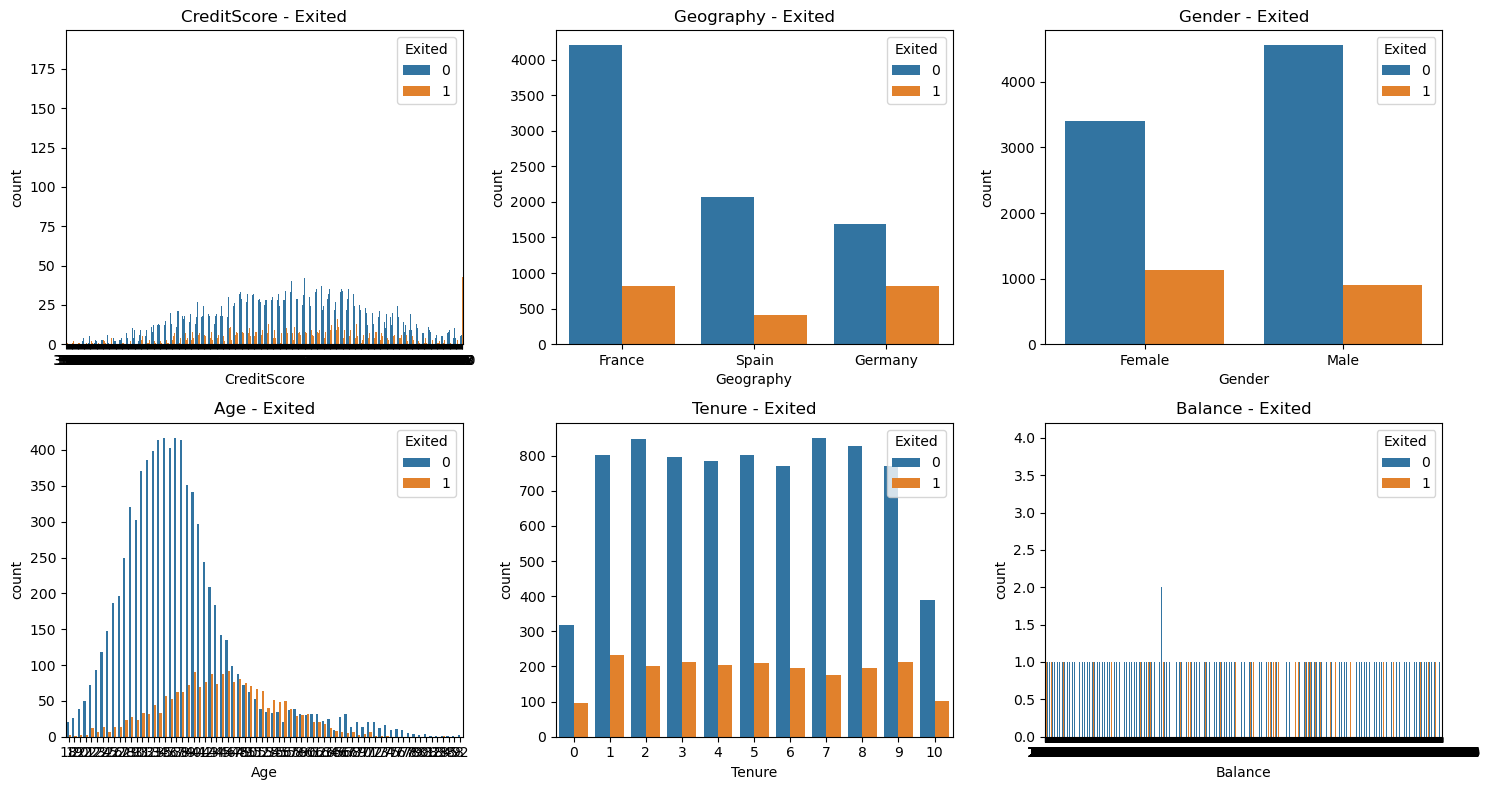

In [13]:
columns1 = ['CreditScore','Geography', 'Gender',
            'Age', 'Tenure', 'Balance' ]

columns_per_line = 3
numb_of_columns = len(columns1)
numb_of_lines = (numb_of_columns + columns_per_line - 1) // columns_per_line

fig, axes = plt.subplots(numb_of_lines, columns_per_line, figsize=(15, 4 * numb_of_lines))
axes = axes.flatten()

for i, col in enumerate(columns1):
    sns.countplot(data=df, x=col, hue='Exited', ax=axes[i])
    axes[i].set_title(f'{col} - Exited')
                          
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

Currently **"CreditScore"**, **"Age"** and **"Balance"** bar plots aren't legible, so let's display them separately.

In [14]:
df['CreditScore'].describe()

count    10000.000000
mean       650.528800
std         96.653299
min        350.000000
25%        584.000000
50%        652.000000
75%        718.000000
max        850.000000
Name: CreditScore, dtype: float64

In [15]:
df["Age"].describe()

count    10000.000000
mean        38.921800
std         10.487806
min         18.000000
25%         32.000000
50%         37.000000
75%         44.000000
max         92.000000
Name: Age, dtype: float64

In [16]:
df["Balance"].describe()

count     10000.000000
mean      78125.373488
std       60413.974301
min          14.000000
25%        6309.000000
50%       97198.540000
75%      127644.240000
max      250898.090000
Name: Balance, dtype: float64

In [17]:
df["EstimatedSalary"].describe()

count     10000.000000
mean     100090.239881
std       57510.492818
min          11.580000
25%       51002.110000
50%      100193.915000
75%      149388.247500
max      199992.480000
Name: EstimatedSalary, dtype: float64

Text(0.5, 1.0, 'Age distribution')

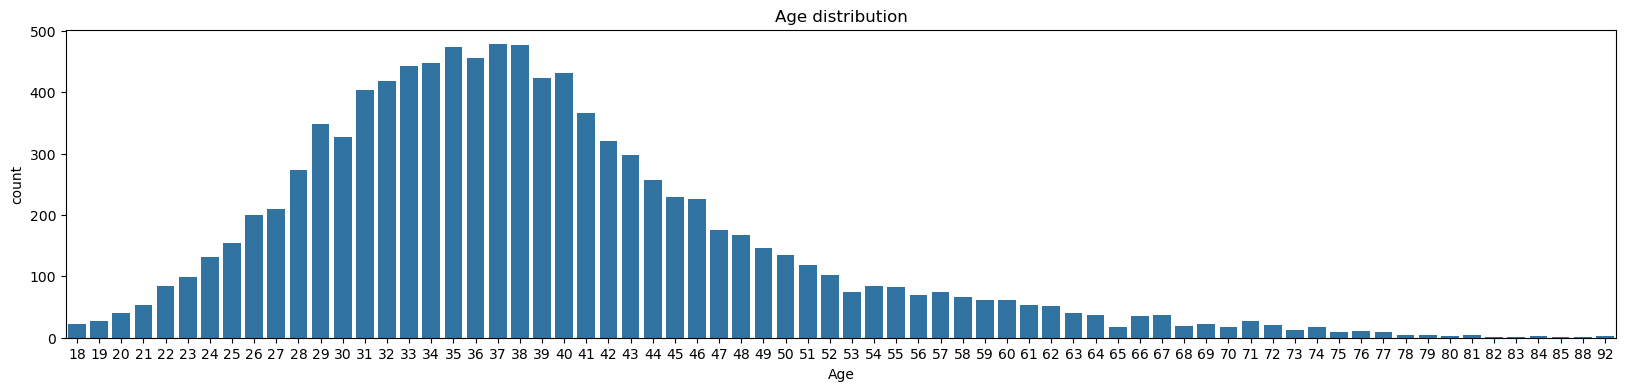

In [18]:
plt.figure(figsize=(20,4))
sns.countplot(df, x='Age')
plt.title('Age distribution')

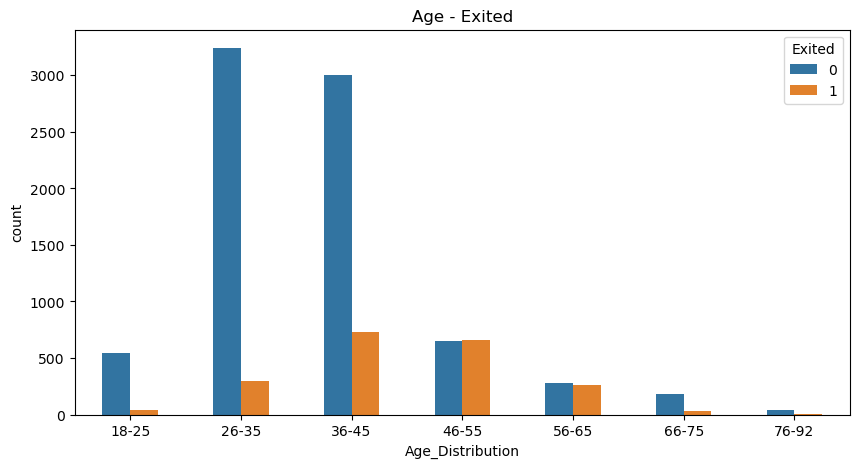

In [19]:
plt.figure(figsize=(10, 5))
age_bins = [18, 25, 35, 45, 55, 65, 75, 92]
age_labels = ['18-25', '26-35', '36-45', '46-55', '56-65', '66-75', '76-92']
df['Age_Distribution'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

sns.countplot(data=df, x='Age_Distribution', hue='Exited',width=0.5)
plt.title('Age - Exited')
plt.legend(title='Exited', loc='upper right')
plt.show()

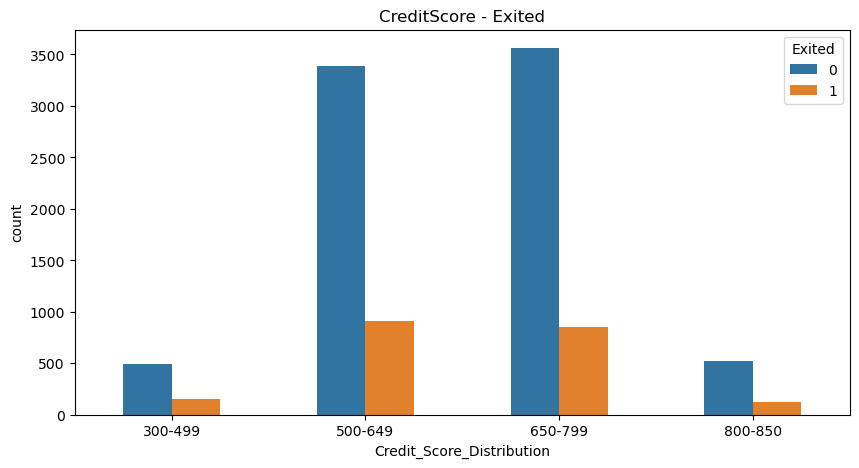

In [20]:
plt.figure(figsize=(10,5))
bins = [300, 500, 650, 800, 850]  
labels = ['300-499', '500-649', '650-799', '800-850']
df['Credit_Score_Distribution'] = pd.cut(df['CreditScore'], bins=bins, labels=labels)

sns.countplot(data=df, x='Credit_Score_Distribution', hue='Exited',width=0.5)
plt.title('CreditScore - Exited')
plt.legend(title='Exited', loc='upper right')
plt.show()

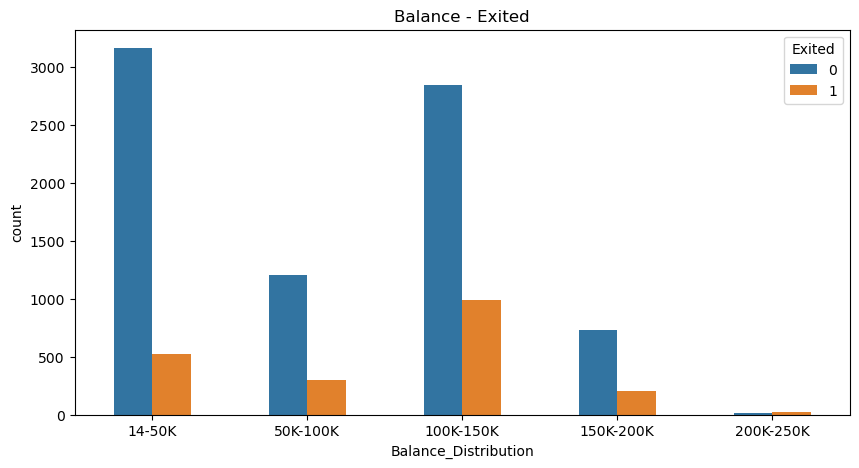

In [21]:
plt.figure(figsize=(10, 5))
balance_bins = [14, 50000, 100000, 150000, 200000, 250898.09]
balance_labels = ['14-50K', '50K-100K', '100K-150K', '150K-200K', '200K-250K']
df['Balance_Distribution'] = pd.cut(df['Balance'], bins=balance_bins, labels=balance_labels)

sns.countplot(data=df, x='Balance_Distribution', hue='Exited',width=0.5)
plt.title('Balance - Exited')
plt.legend(title='Exited', loc='upper right')
plt.show()

Now lets compare some "CreditScore", "Age", "Balance" and "EstimatedSalary" with the "Exited".


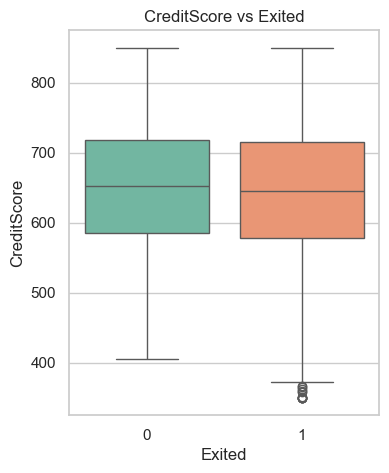

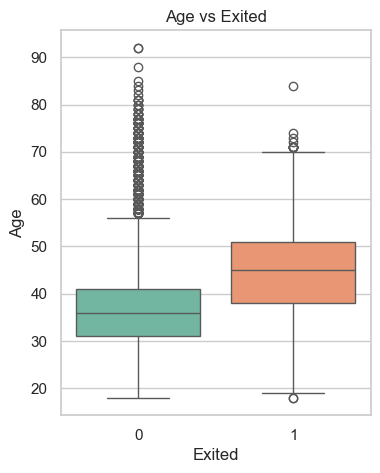

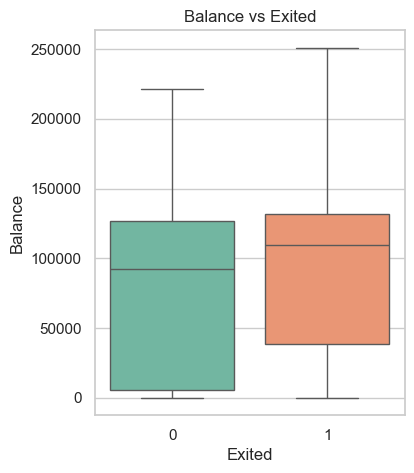

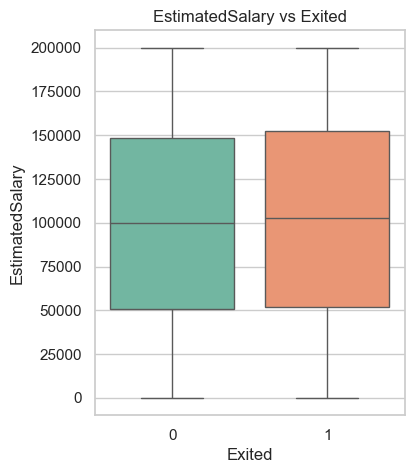

In [42]:
sns.set(style="whitegrid")

# Boxplots
features = ['CreditScore', 'Age', 'Balance', 'EstimatedSalary']
for feature in features:
    plt.figure(figsize=(4,5))
    sns.boxplot(x='Exited', y=feature, data=df, palette='Set2', hue='Exited', legend=False)
    plt.title(f'{feature} vs Exited')
    plt.show()


According to four boxplot comparisons above, older customers or high balance customers are more at risk of churnging, CreditScore has some influence but it'S not strong alone and Salary does not seem important by itself.

Let's find out if a group of older clients really keep more money in the bank than younger clients.

In [23]:
conditions = [
    (df['Age'] >= 76) & (df['Age'] <= 92),
    (df['Age'] >= 28) & (df['Age'] <= 44)
]

choices = ['76-92', '28-44']
df['AgeGroup'] = np.select(conditions, choices, default='Other')

filtered_df = df[df['AgeGroup'].isin(['76-92', '28-44'])]

grouped = filtered_df.groupby('AgeGroup').agg(
    Total_Balance=('Balance', 'sum'),
    Total_Salary=('EstimatedSalary', 'sum'),
    Customer_Count=('CustomerID', 'count')
).reset_index()

total_balance_all = filtered_df['Balance'].sum()
grouped['Balance_Percentage'] = grouped['Total_Balance'] / total_balance_all * 100

print(grouped)

  AgeGroup  Total_Balance  Total_Salary  Customer_Count  Balance_Percentage
0    28-44   5.113180e+08  6.616910e+08            6640           99.413679
1    76-92   3.015648e+06  4.576538e+06              45            0.586321


In [24]:
older_customers = df[(df['Age'] >= 76) & (df['Age'] <= 92)]


In [25]:
count_older = older_customers.shape[0]

print(f"There are {count_older} customers aged between 76 and 92.")

There are 45 customers aged between 76 and 92.


In [26]:
total_balance_older = older_customers['Balance'].sum()

formatted_number = "{:,.0f}".format(total_balance_older)

print(f"Total balance held by customers aged 76-92 is: {formatted_number}")



Total balance held by customers aged 76-92 is: 3,015,648


In [27]:
young_customers = df[(df['Age'] >= 28) & (df['Age'] <=44)]

count_younger = young_customers.shape[0]
print(f"There are {count_younger} customers aged between 28 and 44.")

total_balance_younger = young_customers['Balance'].sum()
formatted_number2 = "{:,.0f}".format(total_balance_younger)

print(f"Total balance held by customers aged 22-44 is: {formatted_number2}")


There are 6640 customers aged between 28 and 44.
Total balance held by customers aged 22-44 is: 511,318,045


In [28]:
avg_balance_older = total_balance_older/45
avg_balance_older_formatted = "{:,.0f}".format(avg_balance_older)
avg_balance_older_formatted

'67,014'

In [29]:
avg_balance_younger = total_balance_younger/6640
avg_balance_younger_formatted = "{:,.0f}".format(avg_balance_younger)
avg_balance_younger_formatted

'77,006'

According to calculations above, Customers (76-92) hold about 3,015.648€ in the bank, while younger group (28-44) holds 511,318.045€ in the bank, also we wanted to see if older group (Even though there are fewer) holds more money in the bank. Turns out they don't, also younger group has higher balance per customer.

<Axes: xlabel='IsActiveMember', ylabel='Age'>

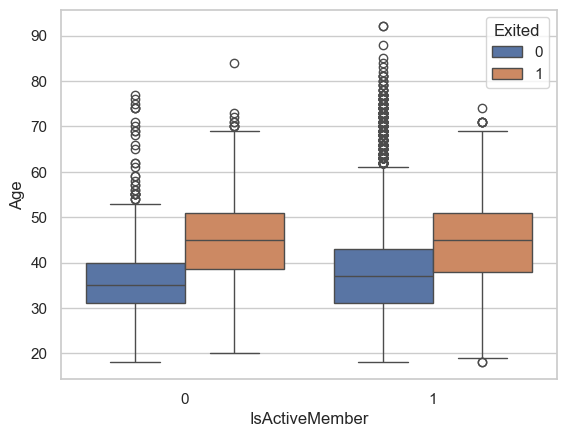

In [30]:
sns.boxplot(x='IsActiveMember', y='Age', hue='Exited', data=df)

Let's try combining  "Age" and "IsActiveMember", "Balance" and "NumOfProducts"  and "Geography" and "CreditScore".

Reason of combining these variables is that maybe customers who are inactive and have high balance are most risky.

<Axes: xlabel='NumOfProducts', ylabel='Balance'>

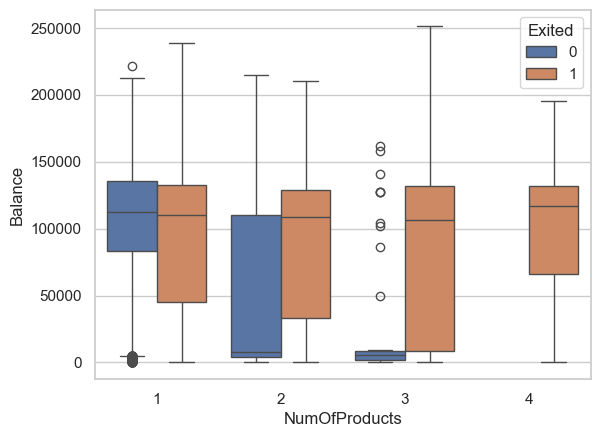

In [31]:
sns.boxplot(x='NumOfProducts', y='Balance', hue='Exited', data=df)

Seeing "Age-IsActiveMember" for both active and inactive customers, churned customers (Exited=1) tend to be older than those who stayed.

The age distribution of churned customers is higher and has more outliers especially among active members.



In [32]:
X = df[['Age', 'CreditScore', 'Balance', 'EstimatedSalary']]  # Choose your features
y = df['Exited']

In [33]:
model = RandomForestClassifier(random_state=42)
model.fit(X, y)

RandomForestClassifier(random_state=42)

In [34]:
importances = model.feature_importances_

In [35]:
feat_importances = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feat_importances.sort_values('Importance', ascending=False, inplace=True)

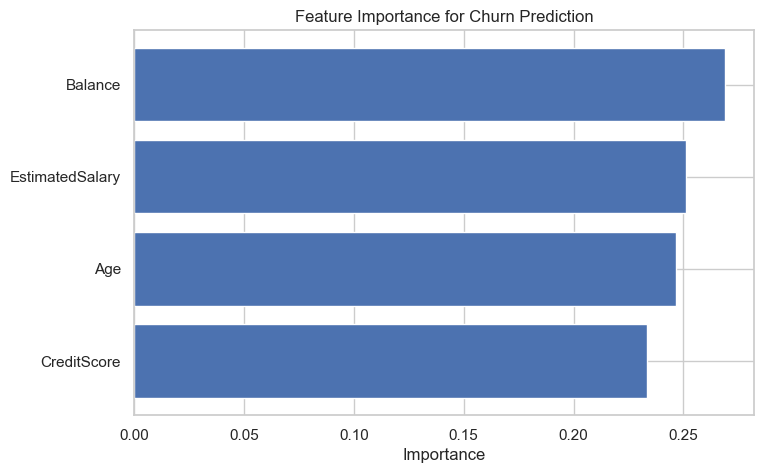

In [36]:
plt.figure(figsize=(8,5))
plt.barh(feat_importances['Feature'], feat_importances['Importance'])
plt.xlabel('Importance')
plt.title('Feature Importance for Churn Prediction')
plt.gca().invert_yaxis()
plt.show()

Before going into detail, Tenure is also an important churn factor,let's check if long term costumers churn more

Tenure
0     0.230024
1     0.224155
2     0.191794
3     0.211100
4     0.205258
5     0.206522
6     0.202689
7     0.172179
8     0.192195
9     0.217480
10    0.206122
Name: Exited, dtype: float64

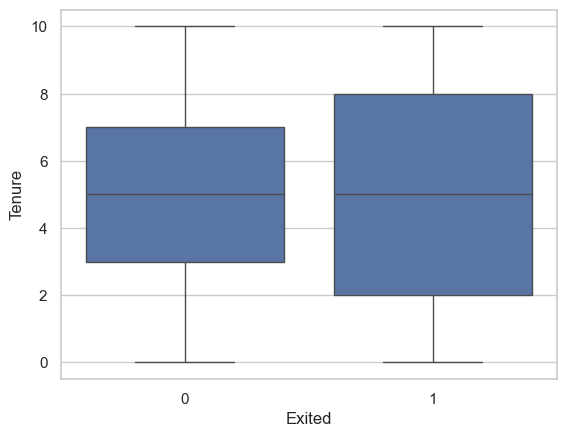

In [37]:
sns.boxplot(x='Exited', y='Tenure', data=df)
df.groupby('Tenure')['Exited'].mean()

So according to these two boxplots above, tenure is a weak churn predictor

In [38]:
df_cor=df.corr(numeric_only=True)

In [39]:
df_cor

,CustomerID,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCreditCard,IsActiveMember,EstimatedSalary,Exited,Complain,SatisfactionsScore,PointEarned
CustomerID,1.000000,0.005308,0.009497,-0.014883,-0.012106,0.016972,-0.014025,0.001665,0.015271,-0.006203,-0.007293,-0.000865,-0.013076
CreditScore,0.005308,1.000000,-0.003965,0.000842,0.006345,0.012238,-0.005458,0.025651,-0.001384,-0.026771,-0.027048,-0.012599,0.000077
Age,0.009497,-0.003965,1.000000,-0.009997,0.027947,-0.030680,-0.011721,0.085472,-0.007201,0.285296,0.283530,-0.000876,0.002222
Tenure,-0.014883,0.000842,-0.009997,1.000000,-0.011630,0.013444,0.022583,-0.028362,0.007784,-0.013656,-0.013047,0.008663,-0.010196
Balance,-0.012106,0.006345,0.027947,-0.011630,1.000000,-0.301975,-0.014868,-0.010214,0.012686,0.118246,0.118780,-0.002761,0.014427
NumOfProducts,0.016972,0.012238,-0.030680,0.013444,-0.301975,1.000000,0.003183,0.009612,0.014204,-0.047611,-0.046357,-0.011394,-0.015330
HasCreditCard,-0.014025,-0.005458,-0.011721,0.022583,-0.014868,0.003183,1.000000,-0.011866,-0.009933,-0.006976,-0.007095,-0.000212,-0.011041
IsActiveMember,0.001665,0.025651,0.085472,-0.028362,-0.010214,0.009612,-0.011866,1.000000,-0.011421,-0.156356,-0.154741,0.010236,-0.004983
EstimatedSalary,0.015271,-0.001384,-0.007201,0.007784,0.012686,0.014204,-0.009933,-0.011421,1.000000,0.012490,0.012494,-0.013747,-0.001515
Exited,-0.006203,-0.026771,0.285296,-0.013656,0.118246,-0.047611,-0.006976,-0.156356,0.012490,1.000000,0.995693,-0.005849,-0.004628
